# Physics-informed modeling (critical-point penalty)

Same GC and Descriptors feature sets, splits and CV as `03_Modeling_GC.ipynb` / `04_Modeling_ML.ipynb`. Both of those already *audit* models post-hoc with `check_tc_violations`: `Surface_tension` must go to ~0 as `T -> TC` (the critical temperature), and a prediction that stays non-negligible near `TC` is flagged as a physical violation.

This notebook goes one step further: it turns that same near-`TC` check into a *training* signal, without ever giving the model `TC` as a feature or asking it to predict `TC`:

- For every training compound, synthetic "collocation" rows are built with the same structural features but `T` replaced by a value very close to that compound's own `TC` (`TC_TR_LEVELS` below), target forced toward 0.
- These rows are only ever used inside `.fit()` (routed in as a `TC=` fit-param, sliced per CV fold by scikit-learn exactly like `X`/`y`) to add a physics penalty term to the training objective. `.predict()` - at CV-validation time, test time, and for any future compound - only ever sees structural features + `T`, never `TC`.
- Applied to the tree ensembles (XGBoost, GradientBoosting, RandomForest) via a sample-weighted augmentation (`PhysicsConstrainedRegressor`), and to a PyTorch MLP via a true gradient-based penalty term in the loss (`TorchPhysicsInformedMLP`).

For a fair comparison, both a plain baseline and a physics-informed variant of every model are fit fresh in *this* notebook (`03`/`04`'s fitted models are never pickled to disk, so there's nothing to reload). Results are saved to separate `metrics_{split}_physics.pkl` files - this notebook never touches `metrics_{split}.pkl` or the `03`/`04`/`05` notebooks. The deliverable is the comparison at the end: does the physics-informed variant show fewer near-`TC` violations than its plain counterpart, for a comparable test RMSE?

# Importing train/test datasets and building X, y

In [10]:
import copy, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from tqdm.auto import tqdm
from scipy.stats import loguniform, randint, uniform

from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV, StratifiedGroupKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (mean_squared_error, mean_absolute_error, root_mean_squared_error,
                             r2_score)
from sklearn.utils.validation import check_is_fitted
from xgboost import XGBRegressor

SPLITS = ['Butina', 'Family']
TARGET = 'Surface_tension'

with open(r"Data and variables/GC_variables.pkl", "rb") as f:
    group_cols = pickle.load(f)["group_cols"]          # group counts + T
with open(r"Data and variables/ML_variables.pkl", "rb") as f:
    descriptor_cols = pickle.load(f)["descriptor_cols"]  # T is not part of this list, so it is appended below

FEATURES = {'GC': group_cols, 'Descriptors': descriptor_cols + ['T']}
FSETS = list(FEATURES)

# Same logic used in 02_ChemicalDataset to build each train/test split:
# StratifiedGroupKFold with groups=ChemID, stratified by Butina cluster or by chemical Family
STRAT_COL = {'Butina': 'cluster_id', 'Family': 'Family'}
GROUP_COL = 'ChemID'
N_CV = 5


def make_cv(train, split, n_splits=N_CV):
    """Explicit CV folds for the training set that preserve how the outer split was built:
    a compound (ChemID) never appears in two folds, and each fold keeps a similar cluster/family mix."""
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=42)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')     # singleton clusters/families can't be stratified
        folds = list(sgkf.split(train, y=train[STRAT_COL[split]], groups=train[GROUP_COL]))
    for tr, va in folds:
        assert set(train.iloc[tr][GROUP_COL]).isdisjoint(train.iloc[va][GROUP_COL])
    return folds


# data[(feature_set, split)] -> X_train, y_train, X_test, y_test and CV folds (folds depend only on the
# split, so both feature sets share them). train_TC/test_meta carry TC alongside, positionally aligned
# with X_train/y_train - TC is only ever consumed as a fit_param, never selected into X.
data = {}
train_TC = {}
test_meta = {}
for s in SPLITS:
    train = pd.read_pickle(rf'Data and variables/train_{s}.pkl')
    test = pd.read_pickle(rf'Data and variables/test_{s}.pkl')
    cv = make_cv(train, s)
    train_TC[s] = train['TC'].reset_index(drop=True)
    test_meta[s] = test[['ChemID', 'Family', 'TC']]
    for fs, cols in FEATURES.items():
        data[(fs, s)] = dict(X_train=train[cols].reset_index(drop=True),
                             y_train=train[TARGET].reset_index(drop=True),
                             X_test=test[cols], y_test=test[TARGET], cv=cv)

# the models cannot handle missing/infinite values
for (fs, s), d in data.items():
    for part in ('X_train', 'X_test'):
        bad = ~np.isfinite(d[part].to_numpy(dtype=float))
        assert not bad.any(), f"{fs}/{s}/{part}: NaN/inf in columns {list(d[part].columns[bad.any(axis=0)])}"
    print(fs, s, d['X_train'].shape, d['X_test'].shape)

# metrics tables (one per split, saved SEPARATELY from 03/04/05's metrics_<split>.pkl), fitted models
# and per-fold CV metrics
COLUMNS = ['description', 'algorithm', 'MSE', 'RMSE', 'MAE', 'SD_error', 'NRMSE_%', 'WAPE_%', 'r2_score']
metrics_paths = {s: rf'Data and variables/metrics_{s}_physics.pkl' for s in SPLITS}
metrics = {}
for s in SPLITS:
    try:
        metrics[s] = pd.read_pickle(metrics_paths[s])
    except FileNotFoundError:
        metrics[s] = pd.DataFrame(columns=COLUMNS)

models = {}      # (algorithm, feature_set, split) -> fitted estimator
cv_folds = {}    # (algorithm, feature_set, split) -> per-fold validation metrics of the best candidate

c:\Users\erfer.LUBRIZOL.000\OneDrive - The Lubrizol Corporation\Documents\Git Repositories\Cheminformatics\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


GC Butina (17058, 30) (8530, 30)
Descriptors Butina (17058, 51) (8530, 51)
GC Family (17101, 30) (8487, 30)
Descriptors Family (17101, 51) (8487, 51)


# Helper functions

Same evaluation/plotting/CV-search helpers as `03`/`04`, adapted so `get_best`/`fit_all` can optionally thread `TC` through as a fit-param.

In [11]:
def get_metrics(model, X_test, y_test, metrics, path, model_desc, algorithm):
    """Evaluate on the test set, add/replace the row in `metrics`, save it and return it."""
    y_pred = model.predict(X_test)
    residuals = y_test - y_pred
    rmse = root_mean_squared_error(y_test, y_pred)

    row = pd.DataFrame([{
        'description': model_desc,
        'algorithm': algorithm,
        'MSE': mean_squared_error(y_test, y_pred),
        'RMSE': rmse,
        'MAE': mean_absolute_error(y_test, y_pred),
        'SD_error': np.std(residuals, ddof=1),
        'NRMSE_%': rmse / np.mean(y_test) * 100,
        'WAPE_%': residuals.abs().sum() / y_test.abs().sum() * 100,
        'r2_score': r2_score(y_test, y_pred),
    }])

    keep = ~((metrics['description'] == model_desc) & (metrics['algorithm'] == algorithm))
    metrics = pd.concat([metrics[keep], row], ignore_index=True)
    metrics.to_pickle(path)
    return metrics


CV_SCORING = {'RMSE': 'neg_root_mean_squared_error', 'MAE': 'neg_mean_absolute_error', 'r2': 'r2',
              'MSE': 'neg_mean_squared_error'}


def get_best(reg, params, X, y, cv, TC=None, n_iter=50, n_jobs=-1):
    """Randomized search selecting on MSE. If `TC` is given it's forwarded as a fit_param - scikit-learn
    slices it per CV fold by position, exactly like X/y, so a fold never sees another fold's TC values, and
    it's never part of X. Returns (best estimator, per-fold metrics of the best candidate)."""
    rcv = RandomizedSearchCV(reg, params, n_iter=n_iter, cv=cv, scoring=CV_SCORING, refit='MSE',
                             random_state=42, n_jobs=n_jobs)
    fit_kwargs = {} if TC is None else {'TC': TC}
    rcv.fit(X, y, **fit_kwargs)
    res, i = rcv.cv_results_, rcv.best_index_
    n_folds = rcv.n_splits_
    folds = pd.DataFrame({
        'fold': range(1, n_folds + 1),
        'n_val': [len(v) for _, v in cv],
        'RMSE': [-res[f'split{k}_test_RMSE'][i] for k in range(n_folds)],
        'MAE': [-res[f'split{k}_test_MAE'][i] for k in range(n_folds)],
        'r2': [res[f'split{k}_test_r2'][i] for k in range(n_folds)],
    }).set_index('fold')
    print('best params:', rcv.best_params_)
    return rcv.best_estimator_, folds


def show_folds(folds, title):
    summary = pd.DataFrame({'mean': folds[['RMSE', 'MAE', 'r2']].mean(), 'std': folds[['RMSE', 'MAE', 'r2']].std()}).T
    print(f'CV metrics per fold - {title}')
    display(pd.concat([folds, summary]).round(3))


def plot_actual_vs_predicted(model, X_test, y_test, title):
    y_pred = model.predict(X_test)
    plt.figure(figsize=(6, 6))
    plt.scatter(y_test, y_pred, alpha=0.5)
    mn, mx = min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())
    plt.plot([mn, mx], [mn, mx], 'r--')
    plt.xlabel('Actual')
    plt.ylabel('Predicted')
    plt.text(0.05, 0.95, f'{title}\nR² = {r2_score(y_test, y_pred):.3f}',
             transform=plt.gca().transAxes, va='top', bbox=dict(facecolor='white', alpha=0.8))
    plt.show()


def record(model, algorithm, fs, split):
    d = data[(fs, split)]
    metrics[split] = get_metrics(model, d['X_test'], d['y_test'], metrics[split],
                                 metrics_paths[split], fs, algorithm)
    models[(algorithm, fs, split)] = model


def prefix_params(params, prefix):
    """Nest a flat param grid under a meta-estimator's sub-estimator, e.g. for
    PhysicsConstrainedRegressor(estimator=...): 'max_depth' -> 'estimator__max_depth'."""
    return {f'{prefix}{k}': v for k, v in params.items()}


def fit_all(label, build_reg, params, pass_tc, n_iter=50, plot=True, n_jobs=-1):
    """For every feature set and split: tune a fresh `build_reg()` with randomized CV (grouped by ChemID,
    stratified like the split), evaluate on the test set and store the results under `label` (e.g.
    'XGBoost' or 'XGBoost_physics'). `pass_tc` controls whether TC is forwarded as a fit_param - True for
    every physics-capable estimator (a PhysicsConstrainedRegressor, or the Torch model even when its own
    lambda_physics is fixed to 0 as a baseline), False for a plain TC-unaware base estimator."""
    for fs in FSETS:
        for s in SPLITS:
            print(f'--- {label} | {fs} | {s} split ---')
            d = data[(fs, s)]
            TC = train_TC[s] if pass_tc else None
            best, folds = get_best(build_reg(), params, d['X_train'], d['y_train'], cv=d['cv'], TC=TC,
                                   n_iter=n_iter, n_jobs=n_jobs)
            cv_folds[(label, fs, s)] = folds
            show_folds(folds, f'{label} ({fs}, {s})')
            record(best, label, fs, s)
            if plot:
                plot_actual_vs_predicted(best, d['X_test'], d['y_test'], f'{label} ({fs}, {s})')


def check_tc_violations(algorithm, fs, split, tr_thresholds=(0.90, 0.95, 0.98, 0.99), zero_tol=2.0, worst_n=15):
    """Physical sanity check on the TEST set only: Surface_tension must go to ~0 as T approaches the
    critical temperature TC. TC/Tr are never used as model inputs - they're pulled in here purely to
    audit predictions. A "violation" is a near-TC test row where the model still predicts a
    non-negligible value (> zero_tol mN/m). Reports counts at several T/TC cutoffs plus the worst
    offenders, since "near TC" has no single correct definition."""
    d = data[(fs, split)]
    model = models[(algorithm, fs, split)]
    meta = test_meta[split]
    y_pred = model.predict(d['X_test'])
    title = f'{algorithm} ({fs}, {split})'

    detail = pd.DataFrame({
        'ChemID': meta['ChemID'].values,
        'Family': meta['Family'].values,
        'T': d['X_test']['T'].values,
        'TC': meta['TC'].values,
        'actual': d['y_test'].values,
        'predicted': y_pred,
    })
    detail['Tr'] = detail['T'] / detail['TC']

    summary = pd.DataFrame([
        {
            'T/TC >=': thr,
            'n_rows': int((detail['Tr'] >= thr).sum()),
            'n_violations': int(((detail['Tr'] >= thr) & (detail['predicted'] > zero_tol)).sum()),
        }
        for thr in tr_thresholds
    ])
    print(f'Critical-point violations (predicted Surface_tension > {zero_tol} mN/m near TC) - {title}')
    display(summary)

    near_tc = detail[detail['Tr'] >= min(tr_thresholds)]
    worst = near_tc[near_tc['predicted'] > zero_tol].sort_values('Tr', ascending=False)
    if len(worst):
        print(f'{min(len(worst), worst_n)} worst violations (closest to TC, by T/TC) - {title}')
        display(worst.head(worst_n).round(3))
    else:
        print(f'No violations found at the loosest threshold tested (T/TC >= {min(tr_thresholds)}).')

    return detail


def tc_violation_counts(algorithm, fs, split, tr_thresholds=(0.90, 0.95, 0.98, 0.99), zero_tol=2.0):
    """Same violation definition as check_tc_violations, but just the counts (no plots/prints) - for
    building compact baseline-vs-physics-informed comparison tables across every model/feature-set/split."""
    d = data[(fs, split)]
    model = models[(algorithm, fs, split)]
    meta = test_meta[split]
    y_pred = model.predict(d['X_test'])
    Tr = d['X_test']['T'].values / meta['TC'].values
    return pd.DataFrame([
        {'algorithm': algorithm, 'feature_set': fs, 'split': split, 'T/TC >=': thr,
         'n_rows': int((Tr >= thr).sum()),
         'n_violations': int(((Tr >= thr) & (y_pred > zero_tol)).sum())}
        for thr in tr_thresholds
    ])

# Physics-informed building blocks

`TC_TR_LEVELS` sets how close to the critical point the synthetic collocation points are placed (as a fraction of each compound's own TC); `ZERO_TOL` is the same tolerance `check_tc_violations` already uses, so a model is only penalized for genuinely violating the physical law, not for a small, physically-reasonable residual.

In [12]:
TC_TR_LEVELS = (0.99, 1.0)   # kept small (2 levels) to limit augmented-dataset size during CV search
ZERO_TOL = 2.0               # same tolerance as check_tc_violations' default


def make_collocation(X, TC, t_col='T', tr_levels=TC_TR_LEVELS):
    """One synthetic row per (real row, tr_level): same structural features, T replaced by tr_level * TC.
    These are deliberately out-of-distribution (near/at the critical point, rarely densely sampled in the
    real data) - that's the point: inject the known asymptotic physics where data is sparse. A handful of
    DIPPR compounds have no recorded TC (~19/17058 in the training data) - those rows are excluded here
    (they still train normally on the real data loss, they just can't contribute a collocation constraint)."""
    mask = TC.notna().to_numpy()
    X, TC = X.loc[mask].reset_index(drop=True), TC.loc[mask].reset_index(drop=True)
    rows = []
    for tr in tr_levels:
        x = X.copy()
        x[t_col] = tr * TC.to_numpy()
        rows.append(x)
    return pd.concat(rows, ignore_index=True)

### Tree ensembles - sample-weighted collocation rows

`PhysicsConstrainedRegressor` wraps any estimator whose `.fit()` accepts `sample_weight` (XGBoost, GradientBoosting, RandomForest all do). `.fit()` appends the synthetic near-TC rows (target 0, weighted by `collocation_weight` relative to the real rows' weight of 1.0) before delegating to the wrapped estimator. `.predict()` never sees or needs TC - nested hyperparameters of the wrapped estimator are addressed as `estimator__<param>` (same convention scikit-learn itself uses for meta-estimators).

In [13]:
class PhysicsConstrainedRegressor(BaseEstimator, RegressorMixin):
    def __init__(self, estimator=None, t_col='T', tr_levels=TC_TR_LEVELS, collocation_weight=0.3):
        self.estimator = estimator
        self.t_col = t_col
        self.tr_levels = tr_levels
        self.collocation_weight = collocation_weight

    def fit(self, X, y, TC=None, sample_weight=None):
        X = pd.DataFrame(X).reset_index(drop=True)
        y = pd.Series(np.asarray(y)).reset_index(drop=True)
        TC = pd.Series(np.asarray(TC)).reset_index(drop=True)

        X_colloc = make_collocation(X, TC, self.t_col, self.tr_levels)
        y_colloc = pd.Series(0.0, index=X_colloc.index)
        w_real = np.ones(len(X)) if sample_weight is None else np.asarray(sample_weight)
        w_colloc = np.full(len(X_colloc), self.collocation_weight)

        X_all = pd.concat([X, X_colloc], ignore_index=True)
        y_all = pd.concat([y, y_colloc], ignore_index=True)
        w_all = np.concatenate([w_real, w_colloc])

        self.estimator_ = clone(self.estimator).fit(X_all, y_all, sample_weight=w_all)
        return self

    def predict(self, X):
        check_is_fitted(self, 'estimator_')
        return self.estimator_.predict(X)   # TC never needed/used here

### MLP (PyTorch) - true gradient-based physics loss

Same `[Linear -> BatchNorm -> ReLU -> Dropout]` architecture as `03`/`04`'s `TorchMLPRegressor`, but self-contained (own internal `StandardScaler` for X and y) so the physics penalty can be computed directly in real mN/m units. The training loss becomes `mse(pred, y) + lambda_physics * physics_penalty(pred_collocation)`, with `physics_penalty` a squared hinge that only fires once a collocation prediction exceeds `ZERO_TOL` in magnitude. Collocation tensors are built once per `.fit()` call from that fold's own training rows, and evaluated through the same network at every optimizer step alongside the real batch - one set of weights, two loss terms. Setting `lambda_physics=0.0` reduces this to a plain MLP, used as the baseline so the comparison is a controlled ablation (identical architecture/search space, physics term on vs. off) rather than two differently-implemented models. `predict()` only ever forwards real feature rows; TC plays no part in it.

In [14]:
class TorchPhysicsInformedMLP(BaseEstimator, RegressorMixin):
    """[Linear -> BatchNorm -> ReLU -> Dropout] per hidden layer, then a linear output. Trained with Adam
    (weight_decay = L2), early stopping on a held-out validation slice (data loss only), and a soft penalty
    pushing predictions at synthetic near-TC collocation points toward 0."""

    def __init__(self, hidden_layer_sizes=(64, 32), dropout=0.2, weight_decay=1e-4, lr=1e-3,
                 batch_size=64, max_epochs=200, patience=15, val_size=0.15,
                 lambda_physics=1.0, zero_tol=ZERO_TOL, tr_levels=TC_TR_LEVELS, t_col='T',
                 random_state=42, device=None, progress_bar=True):
        self.hidden_layer_sizes = hidden_layer_sizes
        self.dropout = dropout
        self.weight_decay = weight_decay
        self.lr = lr
        self.batch_size = batch_size
        self.max_epochs = max_epochs
        self.patience = patience
        self.val_size = val_size
        self.lambda_physics = lambda_physics
        self.zero_tol = zero_tol
        self.tr_levels = tr_levels
        self.t_col = t_col
        self.random_state = random_state
        self.device = device
        self.progress_bar = progress_bar

    def _build(self, n_features):
        device = self.device or ('cuda' if torch.cuda.is_available() else 'cpu')
        layers, in_dim = [], n_features
        for h in self.hidden_layer_sizes:
            layers += [nn.Linear(in_dim, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(self.dropout)]
            in_dim = h
        layers.append(nn.Linear(in_dim, 1))
        return nn.Sequential(*layers).to(device), device

    def fit(self, X, y, TC=None):
        torch.manual_seed(self.random_state)
        X = pd.DataFrame(X).reset_index(drop=True)
        y = np.asarray(y, dtype=np.float32).reshape(-1, 1)
        TC = pd.Series(np.asarray(TC, dtype=np.float32)).reset_index(drop=True)

        self.feature_names_ = list(X.columns)
        t_idx = self.feature_names_.index(self.t_col)

        self.x_scaler_ = StandardScaler().fit(X.to_numpy(dtype=np.float32))
        self.y_scaler_ = StandardScaler().fit(y)

        Xs = self.x_scaler_.transform(X.to_numpy(dtype=np.float32))
        ys = self.y_scaler_.transform(y)

        # Held out purely for early stopping - a plain random split, not grouped by ChemID (same
        # simplification as 03/04's TorchMLPRegressor): only meant to catch overfitting within this fit.
        X_tr, X_val, y_tr, y_val, TC_tr, _ = train_test_split(
            Xs, ys, TC, test_size=self.val_size, random_state=self.random_state)

        self.model_, self.device_ = self._build(Xs.shape[1])
        opt = torch.optim.Adam(self.model_.parameters(), lr=self.lr, weight_decay=self.weight_decay)
        mse = nn.MSELoss()

        X_tr_t = torch.tensor(X_tr, device=self.device_)
        y_tr_t = torch.tensor(y_tr, device=self.device_)
        X_val_t = torch.tensor(X_val, device=self.device_)
        y_val_t = torch.tensor(y_val, device=self.device_)

        # Collocation inputs, built once from this fit's own training rows: real features, T swapped for
        # tr_level * TC. Unscale/rescale through x_scaler_ so T is overwritten in real units, not standardized.
        # A handful of DIPPR compounds have no recorded TC (~19/17058 in the training data) - excluded here
        # (they still train normally on the real data loss, they just can't contribute a collocation point).
        valid = ~np.isnan(TC_tr.to_numpy())
        X_tr_raw = self.x_scaler_.inverse_transform(X_tr)[valid]
        TC_tr_valid = TC_tr.to_numpy()[valid]
        X_colloc_t = None
        if len(X_tr_raw):
            colloc_raw = []
            for tr in self.tr_levels:
                x = X_tr_raw.copy()
                x[:, t_idx] = tr * TC_tr_valid
                colloc_raw.append(x)
            X_colloc_t = torch.tensor(self.x_scaler_.transform(np.concatenate(colloc_raw, axis=0)),
                                      dtype=torch.float32, device=self.device_)

        y_mean, y_std = float(self.y_scaler_.mean_[0]), float(self.y_scaler_.scale_[0])

        def physics_penalty(pred_std):
            pred_real = pred_std * y_std + y_mean   # penalty threshold (ZERO_TOL) is in real mN/m units
            return torch.relu(pred_real.abs() - self.zero_tol).pow(2).mean()

        rng = np.random.default_rng(self.random_state)
        best_val, best_state, best_optimizer_state, best_epoch, stall, epoch = np.inf, None, None, 0, 0, 0
        history = {'epoch': [], 'train_loss': [], 'val_loss': [], 'train_r2': [], 'val_r2': []}

        pbar = tqdm(range(self.max_epochs), desc='MLP training', disable=not self.progress_bar, leave=False)
        for epoch in pbar:
            self.model_.train()
            perm = rng.permutation(len(X_tr_t))
            for start in range(0, len(perm), self.batch_size):
                idx = perm[start:start + self.batch_size]
                if len(idx) < 2:
                    continue   # BatchNorm needs >=2 samples per batch in train mode
                idx_t = torch.as_tensor(idx, dtype=torch.long, device=self.device_)
                opt.zero_grad()
                pred = self.model_(X_tr_t[idx_t])
                loss = mse(pred, y_tr_t[idx_t])
                if self.lambda_physics and X_colloc_t is not None:
                    loss = loss + self.lambda_physics * physics_penalty(self.model_(X_colloc_t))
                loss.backward()
                opt.step()

            # full-batch eval, for the loss/R2-vs-epoch curves and the early-stopping check (data loss only,
            # so model selection isn't skewed by the physics term - it still drove gradient updates above)
            self.model_.eval()
            with torch.no_grad():
                train_pred = self.model_(X_tr_t)
                val_pred = self.model_(X_val_t)
                train_loss = mse(train_pred, y_tr_t).item()
                val_loss = mse(val_pred, y_val_t).item()

            history['epoch'].append(epoch)
            history['train_loss'].append(train_loss)
            history['val_loss'].append(val_loss)
            history['train_r2'].append(r2_score(y_tr, train_pred.cpu().numpy()))
            history['val_r2'].append(r2_score(y_val, val_pred.cpu().numpy()))

            if val_loss < best_val - 1e-6:
                best_val, best_epoch, stall = val_loss, epoch, 0
                # Checkpoint both the model AND the optimizer at the best epoch so far - restoring only
                # the model would leave a resumed fit with stale Adam momentum/variance estimates.
                best_state = {k: v.clone() for k, v in self.model_.state_dict().items()}
                best_optimizer_state = copy.deepcopy(opt.state_dict())
            else:
                stall += 1
            pbar.set_postfix(train_loss=f'{train_loss:.4f}', val_loss=f'{val_loss:.4f}',
                             best_val=f'{best_val:.4f}', stall=stall)
            if stall >= self.patience:
                break
        pbar.close()

        self.model_.load_state_dict(best_state)
        self.optimizer_state_dict_ = best_optimizer_state   # checkpointed alongside model_, for resuming training
        self.n_epochs_, self.best_val_loss_, self.best_epoch_ = epoch + 1, best_val, best_epoch
        self.history_ = history
        return self

    def predict(self, X):
        check_is_fitted(self, 'model_')
        X = pd.DataFrame(X)[self.feature_names_].to_numpy(dtype=np.float32)
        Xs = self.x_scaler_.transform(X)
        self.model_.eval()
        with torch.no_grad():
            pred_std = self.model_(torch.tensor(Xs, device=self.device_)).cpu().numpy()
        return self.y_scaler_.inverse_transform(pred_std).ravel()


def plot_training_curves(algorithm, fs, split, title):
    """Loss and R2 per epoch for a fitted TorchPhysicsInformedMLP, from its training history."""
    net = models[(algorithm, fs, split)]
    h = net.history_

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(h['epoch'], h['train_loss'], label='train')
    axes[0].plot(h['epoch'], h['val_loss'], label='val')
    axes[0].axvline(net.best_epoch_, color='gray', linestyle='--', label='best epoch')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('MSE loss (standardized y, data term only)')
    axes[0].set_title(f'Loss vs Epoch - {title}')
    axes[0].legend()

    axes[1].plot(h['epoch'], h['train_r2'], label='train')
    axes[1].plot(h['epoch'], h['val_r2'], label='val')
    axes[1].axvline(net.best_epoch_, color='gray', linestyle='--', label='best epoch')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('R²')
    axes[1].set_title(f'R² vs Epoch - {title}')
    axes[1].legend()

    plt.tight_layout()
    plt.show()

# Models

Each cell below fits a plain baseline and a physics-informed variant, across both feature sets and both splits. `n_iter` is reduced from `03`/`04`'s defaults (which already differ per algorithm) since every algorithm is now fit twice; lower it further (or drop a feature set) if a cell is too slow.

### XGBoost

--- XGBoost | GC | Butina split ---
best params: {'colsample_bytree': np.float64(0.6002081507981263), 'learning_rate': np.float64(0.112244968336909), 'max_depth': 4, 'min_child_weight': 7, 'n_estimators': 809, 'reg_alpha': np.float64(1.0214946051551315), 'reg_lambda': np.float64(1.752233009446337), 'subsample': np.float64(0.6888431241882921)}
CV metrics per fold - XGBoost (GC, Butina)


,n_val,RMSE,MAE,r2
1,3410.0,3.981,2.364,0.858
2,3410.0,3.852,2.384,0.867
3,3419.0,4.206,2.593,0.864
4,3410.0,3.942,2.395,0.914
5,3409.0,4.095,2.485,0.881
mean,NaN,4.015,2.444,0.877
std,NaN,0.138,0.095,0.022


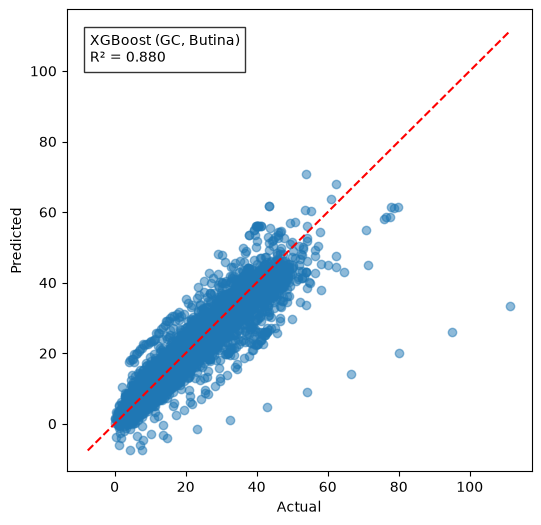

--- XGBoost | GC | Family split ---
best params: {'colsample_bytree': np.float64(0.6431565707973218), 'learning_rate': np.float64(0.019114463849152934), 'max_depth': 8, 'min_child_weight': 1, 'n_estimators': 663, 'reg_alpha': np.float64(1.1265511439527673), 'reg_lambda': np.float64(2.5865482592783824), 'subsample': np.float64(0.6557325817623503)}
CV metrics per fold - XGBoost (GC, Family)


,n_val,RMSE,MAE,r2
1,3426.0,4.022,2.396,0.916
2,3421.0,4.278,2.496,0.850
3,3426.0,4.218,2.354,0.849
4,3410.0,3.963,2.343,0.868
5,3418.0,4.208,2.635,0.877
mean,NaN,4.138,2.445,0.872
std,NaN,0.137,0.122,0.028


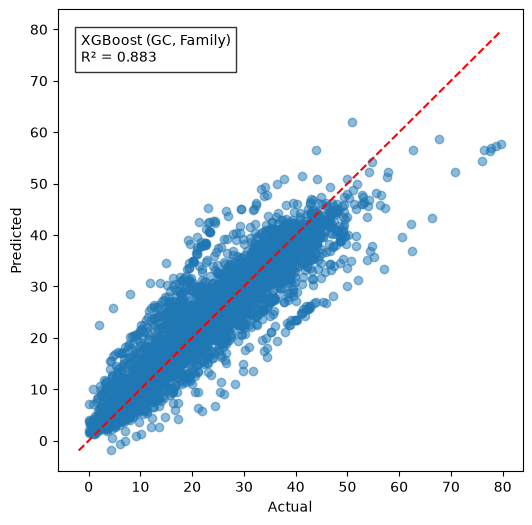

--- XGBoost | Descriptors | Butina split ---
best params: {'colsample_bytree': np.float64(0.6431565707973218), 'learning_rate': np.float64(0.019114463849152934), 'max_depth': 8, 'min_child_weight': 1, 'n_estimators': 663, 'reg_alpha': np.float64(1.1265511439527673), 'reg_lambda': np.float64(2.5865482592783824), 'subsample': np.float64(0.6557325817623503)}
CV metrics per fold - XGBoost (Descriptors, Butina)


,n_val,RMSE,MAE,r2
1,3410.0,3.699,2.078,0.877
2,3410.0,2.944,1.920,0.922
3,3419.0,3.926,2.174,0.882
4,3410.0,3.876,2.377,0.916
5,3409.0,4.316,2.484,0.868
mean,NaN,3.752,2.207,0.893
std,NaN,0.505,0.227,0.024


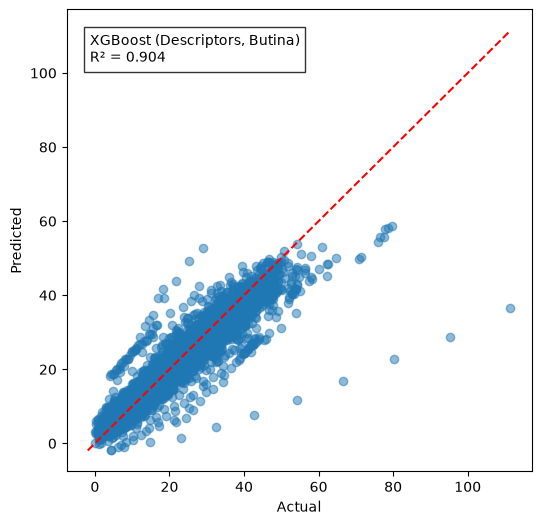

--- XGBoost | Descriptors | Family split ---
best params: {'colsample_bytree': np.float64(0.8430179407605753), 'learning_rate': np.float64(0.059451995869314544), 'max_depth': 8, 'min_child_weight': 2, 'n_estimators': 487, 'reg_alpha': np.float64(1.8844035113697055), 'reg_lambda': np.float64(2.1898646535366177), 'subsample': np.float64(0.7541666010159664)}
CV metrics per fold - XGBoost (Descriptors, Family)


,n_val,RMSE,MAE,r2
1,3426.0,3.955,2.259,0.919
2,3421.0,3.359,2.041,0.908
3,3426.0,3.666,1.967,0.886
4,3410.0,4.009,2.125,0.865
5,3418.0,3.470,2.016,0.916
mean,NaN,3.692,2.082,0.899
std,NaN,0.288,0.114,0.023


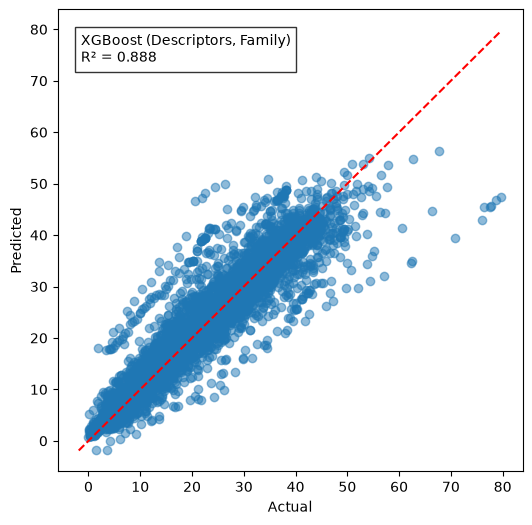

--- XGBoost_physics | GC | Butina split ---
best params: {'collocation_weight': np.float64(0.1600427059120603), 'estimator__colsample_bytree': np.float64(0.7216968971838151), 'estimator__learning_rate': np.float64(0.16217936517334897), 'estimator__max_depth': 5, 'estimator__min_child_weight': 9, 'estimator__n_estimators': 660, 'estimator__reg_alpha': np.float64(1.0495493205167783), 'estimator__reg_lambda': np.float64(1.6995829151457664), 'estimator__subsample': np.float64(0.6186662652854461)}
CV metrics per fold - XGBoost_physics (GC, Butina)


,n_val,RMSE,MAE,r2
1,3410.0,3.773,2.278,0.872
2,3410.0,3.834,2.374,0.868
3,3419.0,4.182,2.576,0.866
4,3410.0,4.102,2.425,0.906
5,3409.0,3.960,2.462,0.889
mean,NaN,3.970,2.423,0.880
std,NaN,0.173,0.110,0.017


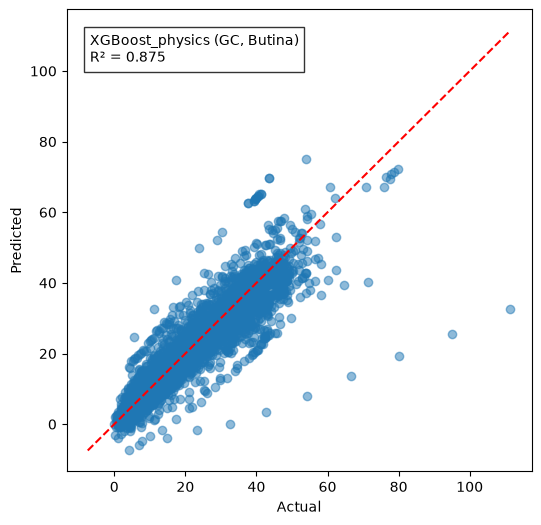

--- XGBoost_physics | GC | Family split ---
best params: {'collocation_weight': np.float64(0.6342533113048755), 'estimator__colsample_bytree': np.float64(0.6931085361721216), 'estimator__learning_rate': np.float64(0.03627586601451803), 'estimator__max_depth': 7, 'estimator__min_child_weight': 3, 'estimator__n_estimators': 975, 'estimator__reg_alpha': np.float64(1.0284688768272232), 'estimator__reg_lambda': np.float64(2.2772437065861273), 'estimator__subsample': np.float64(0.6185801650879991)}
CV metrics per fold - XGBoost_physics (GC, Family)


,n_val,RMSE,MAE,r2
1,3426.0,4.002,2.423,0.917
2,3421.0,4.245,2.457,0.852
3,3426.0,4.325,2.410,0.841
4,3410.0,4.056,2.380,0.862
5,3418.0,4.378,2.660,0.867
mean,NaN,4.201,2.466,0.868
std,NaN,0.165,0.112,0.029


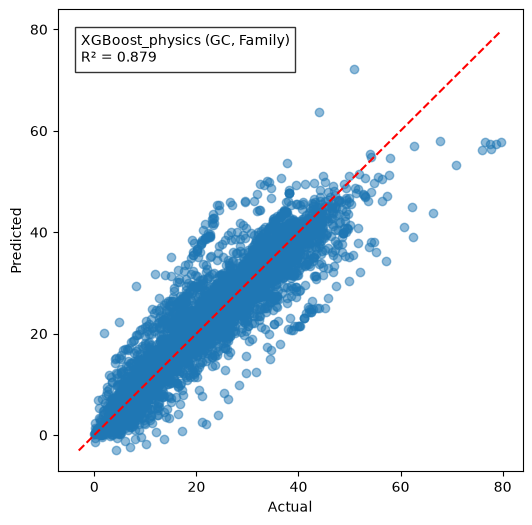

--- XGBoost_physics | Descriptors | Butina split ---
best params: {'collocation_weight': np.float64(0.2502251666834131), 'estimator__colsample_bytree': np.float64(0.6571467271687763), 'estimator__learning_rate': np.float64(0.19875765715516733), 'estimator__max_depth': 6, 'estimator__min_child_weight': 2, 'estimator__n_estimators': 443, 'estimator__reg_alpha': np.float64(1.6648852816008435), 'estimator__reg_lambda': np.float64(1.1370173320348285), 'estimator__subsample': np.float64(0.6727299868828402)}
CV metrics per fold - XGBoost_physics (Descriptors, Butina)


,n_val,RMSE,MAE,r2
1,3410.0,3.509,2.040,0.890
2,3410.0,3.024,1.969,0.918
3,3419.0,4.048,2.295,0.874
4,3410.0,3.872,2.348,0.917
5,3409.0,4.193,2.490,0.876
mean,NaN,3.729,2.228,0.895
std,NaN,0.470,0.218,0.021


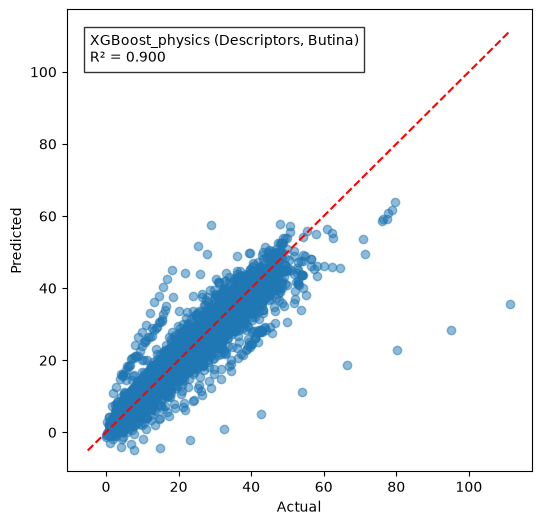

--- XGBoost_physics | Descriptors | Family split ---
best params: {'collocation_weight': np.float64(0.37045365162526517), 'estimator__colsample_bytree': np.float64(0.7939319885435933), 'estimator__learning_rate': np.float64(0.2108064495381784), 'estimator__max_depth': 3, 'estimator__min_child_weight': 8, 'estimator__n_estimators': 926, 'estimator__reg_alpha': np.float64(0.6464058640415105), 'estimator__reg_lambda': np.float64(2.056371865230098), 'estimator__subsample': np.float64(0.881207583558071)}
CV metrics per fold - XGBoost_physics (Descriptors, Family)


,n_val,RMSE,MAE,r2
1,3426.0,4.169,2.280,0.910
2,3421.0,3.135,1.976,0.919
3,3426.0,3.588,1.928,0.890
4,3410.0,4.217,2.253,0.851
5,3418.0,3.314,2.074,0.924
mean,NaN,3.685,2.102,0.899
std,NaN,0.492,0.159,0.030


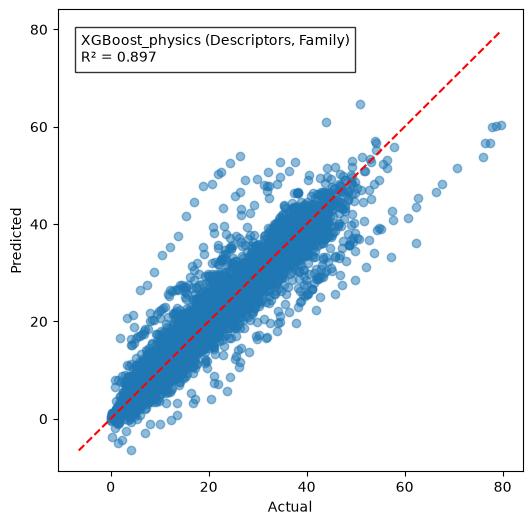

In [15]:
XGB_PARAMS = {
    'n_estimators': randint(100, 1000),
    'max_depth': randint(2, 10),
    'learning_rate': uniform(0.01, 0.29),
    'subsample': uniform(0.6, 0.4),
    'colsample_bytree': uniform(0.6, 0.4),
    'min_child_weight': randint(1, 10),
    'reg_alpha': uniform(0, 2),
    'reg_lambda': uniform(0.5, 3),
}

fit_all('XGBoost', lambda: XGBRegressor(objective='reg:squarederror', random_state=42, n_jobs=1),
        XGB_PARAMS, pass_tc=False, n_iter=20)

fit_all('XGBoost_physics',
        lambda: PhysicsConstrainedRegressor(estimator=XGBRegressor(objective='reg:squarederror',
                                                                   random_state=42, n_jobs=1)),
        {**prefix_params(XGB_PARAMS, 'estimator__'), 'collocation_weight': uniform(0.05, 0.6)},
        pass_tc=True, n_iter=20)

### Gradient Boosting Regressor

--- GradientBoosting | GC | Butina split ---
best params: {'learning_rate': np.float64(0.27051668818999286), 'loss': 'huber', 'max_depth': 5, 'n_estimators': 261, 'subsample': np.float64(0.7580600944007257)}
CV metrics per fold - GradientBoosting (GC, Butina)


,n_val,RMSE,MAE,r2
1,3410.0,4.309,2.487,0.834
2,3410.0,3.667,2.365,0.880
3,3419.0,4.400,2.727,0.852
4,3410.0,4.133,2.453,0.905
5,3409.0,4.255,2.648,0.872
mean,NaN,4.153,2.536,0.868
std,NaN,0.288,0.148,0.027


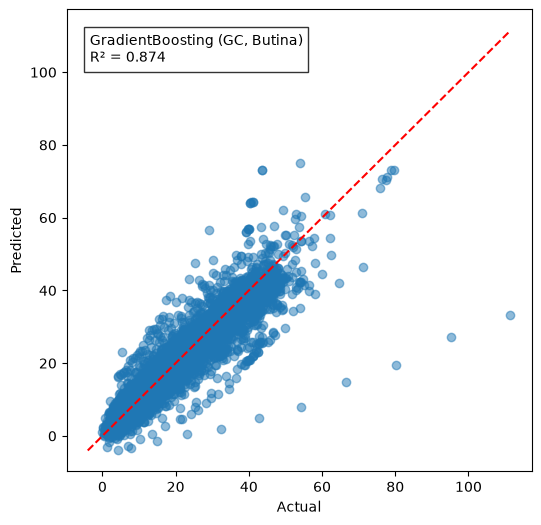

--- GradientBoosting | GC | Family split ---
best params: {'learning_rate': np.float64(0.08167611317882542), 'loss': 'huber', 'max_depth': 7, 'n_estimators': 352, 'subsample': np.float64(0.7727780074568463)}
CV metrics per fold - GradientBoosting (GC, Family)


,n_val,RMSE,MAE,r2
1,3426.0,3.634,2.278,0.932
2,3421.0,4.386,2.508,0.842
3,3426.0,4.357,2.424,0.838
4,3410.0,4.291,2.416,0.845
5,3418.0,4.186,2.639,0.878
mean,NaN,4.171,2.453,0.867
std,NaN,0.310,0.133,0.039


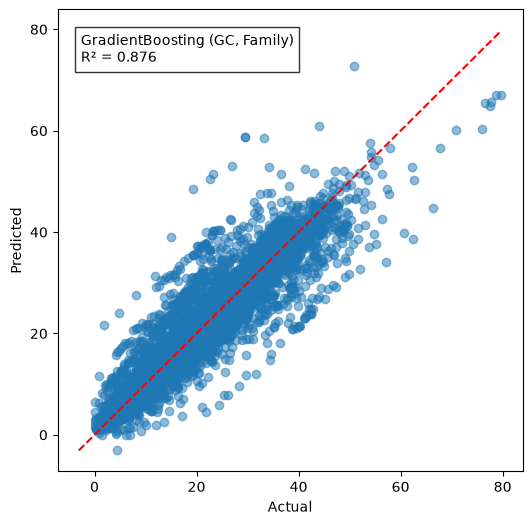

--- GradientBoosting | Descriptors | Butina split ---
best params: {'learning_rate': np.float64(0.1601531217136121), 'loss': 'squared_error', 'max_depth': 4, 'n_estimators': 388, 'subsample': np.float64(0.8423839899124046)}
CV metrics per fold - GradientBoosting (Descriptors, Butina)


,n_val,RMSE,MAE,r2
1,3410.0,3.314,1.942,0.902
2,3410.0,3.167,2.011,0.910
3,3419.0,3.910,2.250,0.883
4,3410.0,3.751,2.254,0.922
5,3409.0,4.346,2.528,0.866
mean,NaN,3.698,2.197,0.897
std,NaN,0.473,0.232,0.022


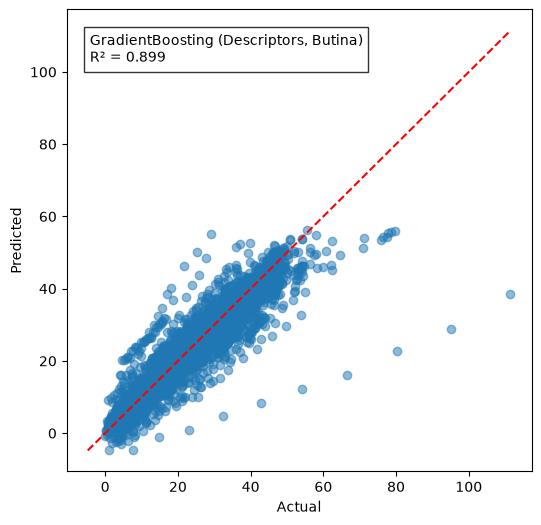

--- GradientBoosting | Descriptors | Family split ---
best params: {'learning_rate': np.float64(0.07357031542417702), 'loss': 'squared_error', 'max_depth': 5, 'n_estimators': 287, 'subsample': np.float64(0.8170784332632994)}
CV metrics per fold - GradientBoosting (Descriptors, Family)


,n_val,RMSE,MAE,r2
1,3426.0,4.308,2.517,0.904
2,3421.0,3.403,2.162,0.905
3,3426.0,3.683,2.000,0.885
4,3410.0,4.090,2.222,0.860
5,3418.0,3.501,2.109,0.915
mean,NaN,3.797,2.202,0.894
std,NaN,0.388,0.194,0.022


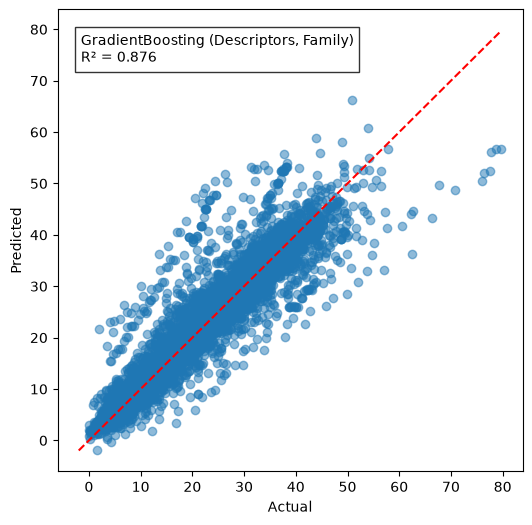

--- GradientBoosting_physics | GC | Butina split ---
best params: {'collocation_weight': np.float64(0.6453269355747305), 'estimator__learning_rate': np.float64(0.08167611317882542), 'estimator__loss': 'huber', 'estimator__max_depth': 7, 'estimator__n_estimators': 352, 'estimator__subsample': np.float64(0.7727780074568463)}
CV metrics per fold - GradientBoosting_physics (GC, Butina)


,n_val,RMSE,MAE,r2
1,3410.0,4.128,2.440,0.847
2,3410.0,3.968,2.516,0.859
3,3419.0,4.364,2.732,0.854
4,3410.0,4.015,2.640,0.910
5,3409.0,4.214,2.667,0.874
mean,NaN,4.138,2.599,0.869
std,NaN,0.159,0.118,0.025


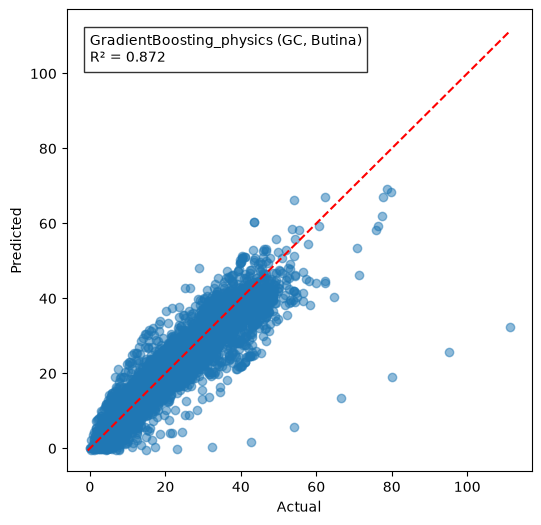

--- GradientBoosting_physics | GC | Family split ---
best params: {'collocation_weight': np.float64(0.6453269355747305), 'estimator__learning_rate': np.float64(0.08167611317882542), 'estimator__loss': 'huber', 'estimator__max_depth': 7, 'estimator__n_estimators': 352, 'estimator__subsample': np.float64(0.7727780074568463)}
CV metrics per fold - GradientBoosting_physics (GC, Family)


,n_val,RMSE,MAE,r2
1,3426.0,4.030,2.527,0.916
2,3421.0,4.313,2.583,0.848
3,3426.0,4.421,2.464,0.834
4,3410.0,4.282,2.542,0.846
5,3418.0,4.301,2.757,0.871
mean,NaN,4.269,2.575,0.863
std,NaN,0.144,0.111,0.033


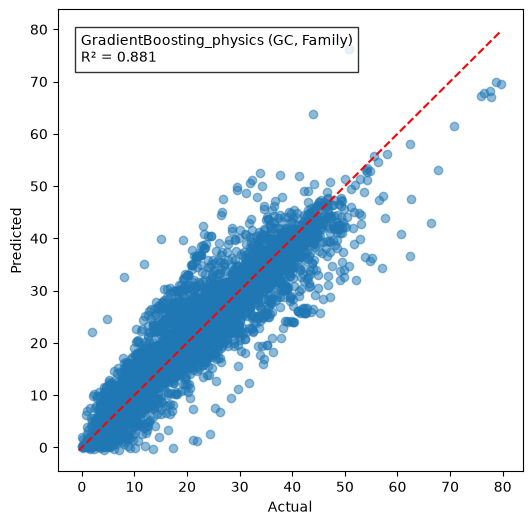

--- GradientBoosting_physics | Descriptors | Butina split ---
best params: {'collocation_weight': np.float64(0.5392768570729005), 'estimator__learning_rate': np.float64(0.11069143219393454), 'estimator__loss': 'squared_error', 'estimator__max_depth': 4, 'estimator__n_estimators': 388, 'estimator__subsample': np.float64(0.8423839899124046)}
CV metrics per fold - GradientBoosting_physics (Descriptors, Butina)


,n_val,RMSE,MAE,r2
1,3410.0,3.548,2.193,0.887
2,3410.0,3.152,2.085,0.911
3,3419.0,4.027,2.290,0.876
4,3410.0,3.998,2.485,0.911
5,3409.0,4.410,2.585,0.862
mean,NaN,3.827,2.328,0.890
std,NaN,0.485,0.206,0.022


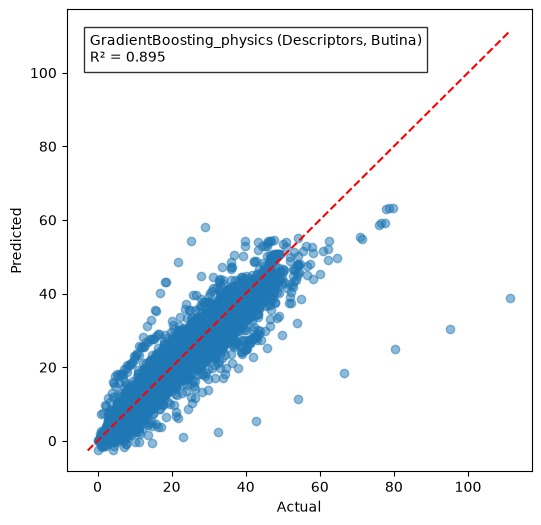

--- GradientBoosting_physics | Descriptors | Family split ---
best params: {'collocation_weight': np.float64(0.5392768570729005), 'estimator__learning_rate': np.float64(0.11069143219393454), 'estimator__loss': 'squared_error', 'estimator__max_depth': 4, 'estimator__n_estimators': 388, 'estimator__subsample': np.float64(0.8423839899124046)}
CV metrics per fold - GradientBoosting_physics (Descriptors, Family)


,n_val,RMSE,MAE,r2
1,3426.0,4.315,2.578,0.904
2,3421.0,3.519,2.251,0.899
3,3426.0,3.748,2.108,0.880
4,3410.0,4.106,2.269,0.858
5,3418.0,3.421,2.147,0.919
mean,NaN,3.822,2.271,0.892
std,NaN,0.381,0.185,0.023


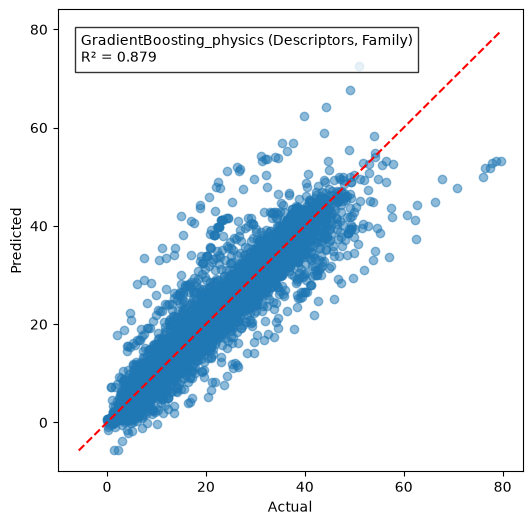

In [16]:
GBM_PARAMS = {
    'n_estimators': randint(100, 500),
    'learning_rate': loguniform(1e-2, 3e-1),
    'max_depth': randint(2, 8),
    'subsample': uniform(0.6, 0.4),
    'loss': ['squared_error', 'huber'],
}

fit_all('GradientBoosting', lambda: GradientBoostingRegressor(random_state=42),
        GBM_PARAMS, pass_tc=False, n_iter=20)

fit_all('GradientBoosting_physics',
        lambda: PhysicsConstrainedRegressor(estimator=GradientBoostingRegressor(random_state=42)),
        {**prefix_params(GBM_PARAMS, 'estimator__'), 'collocation_weight': uniform(0.05, 0.6)},
        pass_tc=True, n_iter=20)

### Random Forest

--- RandomForest | GC | Butina split ---
best params: {'max_depth': None, 'max_features': np.float64(0.61534947637868), 'min_samples_leaf': 2, 'n_estimators': 487}
CV metrics per fold - RandomForest (GC, Butina)


,n_val,RMSE,MAE,r2
1,3410.0,3.868,2.395,0.866
2,3410.0,4.185,2.635,0.843
3,3419.0,4.830,2.783,0.821
4,3410.0,4.333,2.617,0.895
5,3409.0,4.470,2.767,0.859
mean,NaN,4.337,2.639,0.857
std,NaN,0.355,0.156,0.028


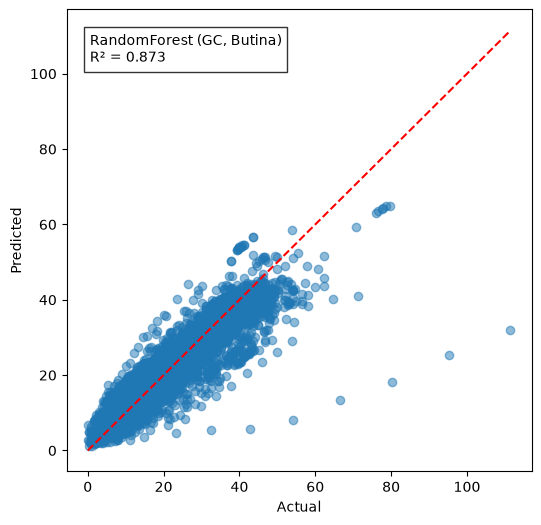

--- RandomForest | GC | Family split ---
best params: {'max_depth': None, 'max_features': np.float64(0.61534947637868), 'min_samples_leaf': 2, 'n_estimators': 487}
CV metrics per fold - RandomForest (GC, Family)


,n_val,RMSE,MAE,r2
1,3426.0,4.154,2.454,0.911
2,3421.0,5.142,2.960,0.783
3,3426.0,4.324,2.470,0.841
4,3410.0,3.995,2.523,0.866
5,3418.0,4.479,2.819,0.860
mean,NaN,4.419,2.645,0.852
std,NaN,0.443,0.230,0.046


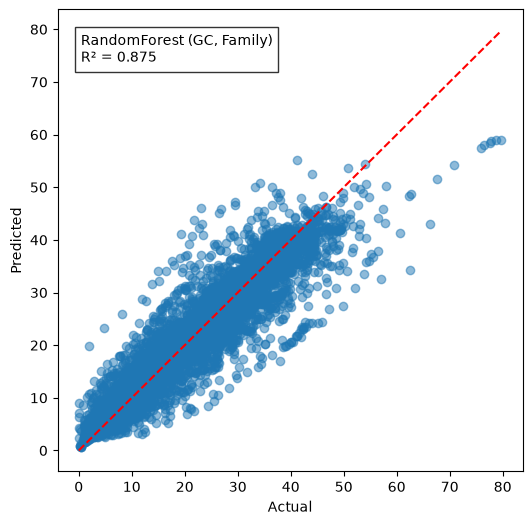

--- RandomForest | Descriptors | Butina split ---
best params: {'max_depth': None, 'max_features': np.float64(0.40921304830970556), 'min_samples_leaf': 3, 'n_estimators': 314}
CV metrics per fold - RandomForest (Descriptors, Butina)


,n_val,RMSE,MAE,r2
1,3410.0,3.971,2.404,0.859
2,3410.0,3.209,2.181,0.908
3,3419.0,4.175,2.408,0.867
4,3410.0,3.885,2.532,0.916
5,3409.0,4.592,2.669,0.851
mean,NaN,3.966,2.439,0.880
std,NaN,0.504,0.181,0.030


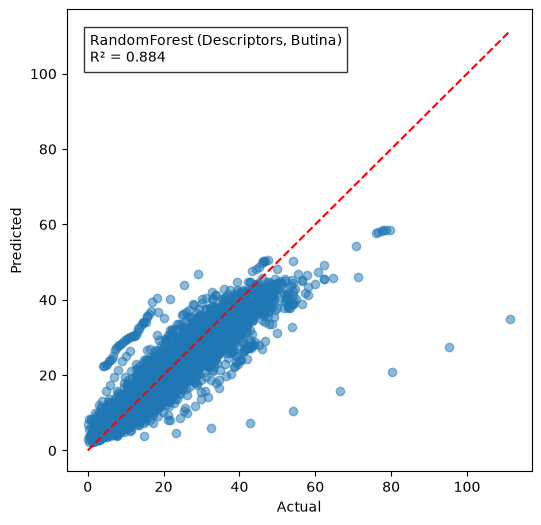

--- RandomForest | Descriptors | Family split ---
best params: {'max_depth': None, 'max_features': np.float64(0.61534947637868), 'min_samples_leaf': 2, 'n_estimators': 487}
CV metrics per fold - RandomForest (Descriptors, Family)


,n_val,RMSE,MAE,r2
1,3426.0,3.895,2.348,0.922
2,3421.0,3.775,2.404,0.883
3,3426.0,3.917,2.207,0.869
4,3410.0,4.540,2.490,0.827
5,3418.0,3.640,2.243,0.908
mean,NaN,3.954,2.339,0.882
std,NaN,0.346,0.116,0.037


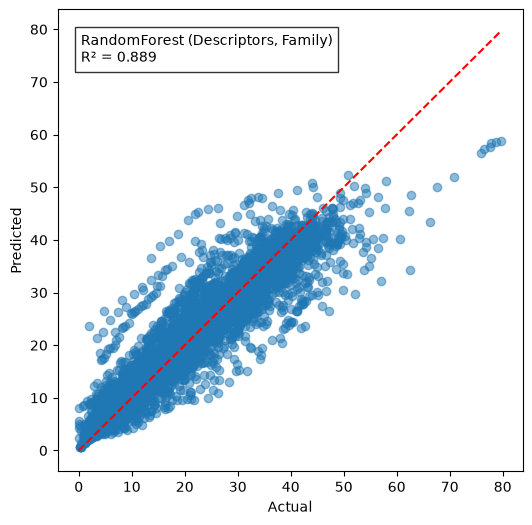

--- RandomForest_physics | GC | Butina split ---
best params: {'collocation_weight': np.float64(0.3625005560154942), 'estimator__max_depth': None, 'estimator__max_features': np.float64(0.5720741027826374), 'estimator__min_samples_leaf': 2, 'estimator__n_estimators': 466}
CV metrics per fold - RandomForest_physics (GC, Butina)


,n_val,RMSE,MAE,r2
1,3410.0,3.817,2.379,0.869
2,3410.0,4.233,2.673,0.839
3,3419.0,4.887,2.807,0.817
4,3410.0,4.343,2.648,0.895
5,3409.0,4.614,2.821,0.849
mean,NaN,4.379,2.666,0.854
std,NaN,0.404,0.178,0.030


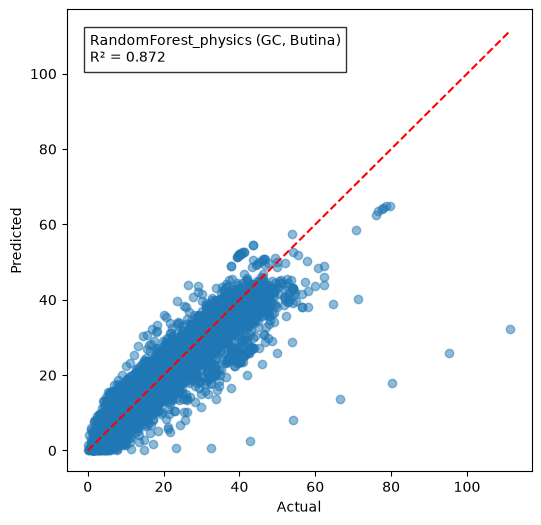

--- RandomForest_physics | GC | Family split ---
best params: {'collocation_weight': np.float64(0.3625005560154942), 'estimator__max_depth': None, 'estimator__max_features': np.float64(0.5720741027826374), 'estimator__min_samples_leaf': 2, 'estimator__n_estimators': 466}
CV metrics per fold - RandomForest_physics (GC, Family)


,n_val,RMSE,MAE,r2
1,3426.0,4.206,2.482,0.909
2,3421.0,5.097,2.931,0.787
3,3426.0,4.363,2.485,0.838
4,3410.0,4.010,2.542,0.865
5,3418.0,4.613,2.880,0.852
mean,NaN,4.458,2.664,0.850
std,NaN,0.420,0.222,0.044


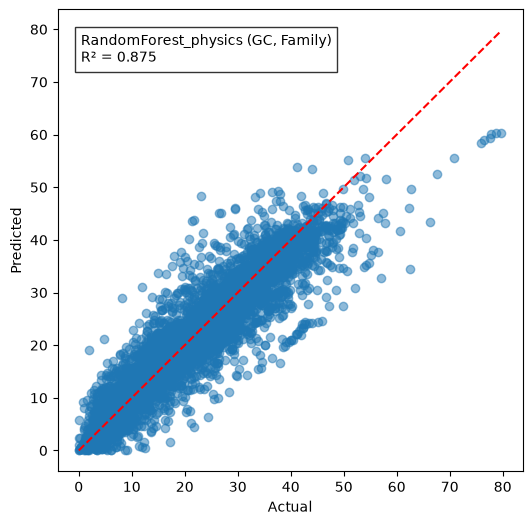

--- RandomForest_physics | Descriptors | Butina split ---
best params: {'collocation_weight': np.float64(0.2325453457757226), 'estimator__max_depth': None, 'estimator__max_features': np.float64(0.602361513049481), 'estimator__min_samples_leaf': 1, 'estimator__n_estimators': 158}
CV metrics per fold - RandomForest_physics (Descriptors, Butina)


,n_val,RMSE,MAE,r2
1,3410.0,4.147,2.362,0.846
2,3410.0,3.230,2.152,0.907
3,3419.0,4.234,2.386,0.863
4,3410.0,3.656,2.328,0.926
5,3409.0,4.433,2.531,0.861
mean,NaN,3.940,2.351,0.880
std,NaN,0.489,0.136,0.034


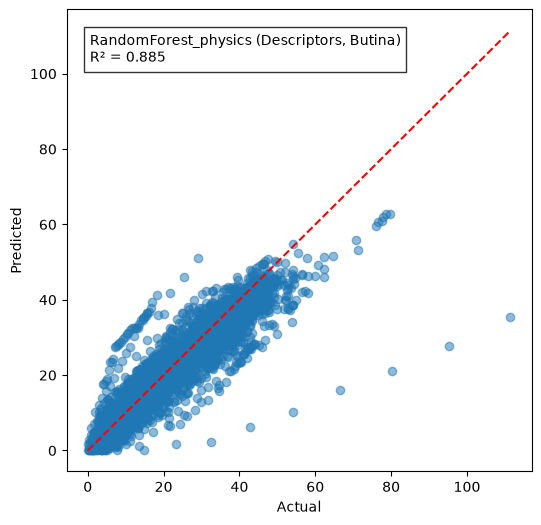

--- RandomForest_physics | Descriptors | Family split ---
best params: {'collocation_weight': np.float64(0.3625005560154942), 'estimator__max_depth': None, 'estimator__max_features': np.float64(0.5720741027826374), 'estimator__min_samples_leaf': 2, 'estimator__n_estimators': 466}
CV metrics per fold - RandomForest_physics (Descriptors, Family)


,n_val,RMSE,MAE,r2
1,3426.0,3.994,2.392,0.918
2,3421.0,3.865,2.431,0.878
3,3426.0,3.905,2.192,0.870
4,3410.0,4.594,2.438,0.823
5,3418.0,3.719,2.255,0.904
mean,NaN,4.016,2.342,0.878
std,NaN,0.338,0.111,0.037


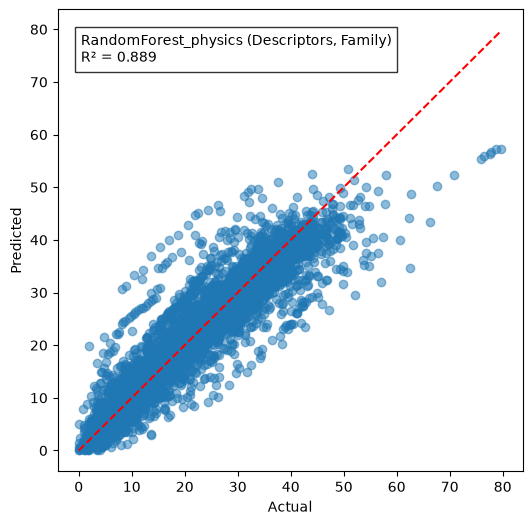

In [17]:
RF_PARAMS = {
    'n_estimators': randint(100, 500),
    'max_depth': [6, 9, 12, 15, None],
    'min_samples_leaf': randint(1, 10),
    'max_features': uniform(0.3, 0.7),
}

fit_all('RandomForest', lambda: RandomForestRegressor(random_state=42, n_jobs=1),
        RF_PARAMS, pass_tc=False, n_iter=20)

fit_all('RandomForest_physics',
        lambda: PhysicsConstrainedRegressor(estimator=RandomForestRegressor(random_state=42, n_jobs=1)),
        {**prefix_params(RF_PARAMS, 'estimator__'), 'collocation_weight': uniform(0.05, 0.6)},
        pass_tc=True, n_iter=20)

### Multilayer Perceptron (PyTorch)

Baseline and physics-informed variants of the *same* class, differing only in whether `lambda_physics` is searched (fixed to 0 for the baseline) - a controlled ablation rather than two separately-implemented models.

--- MLP_PyTorch | GC | Butina split ---


best params: {'dropout': np.float64(0.23338144662398996), 'hidden_layer_sizes': (128, 64, 32), 'lambda_physics': 0.0, 'lr': np.float64(0.0016409286730647919), 'weight_decay': np.float64(4.809461967501575e-06)}
CV metrics per fold - MLP_PyTorch (GC, Butina)


,n_val,RMSE,MAE,r2
1,3410.0,3.220,2.090,0.907
2,3410.0,3.485,2.336,0.891
3,3419.0,6.414,2.928,0.685
4,3410.0,3.322,2.334,0.939
5,3409.0,4.463,2.742,0.859
mean,NaN,4.181,2.486,0.856
std,NaN,1.343,0.340,0.100


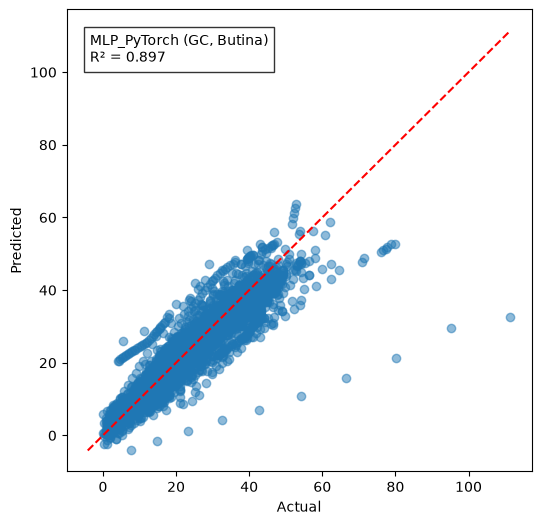

--- MLP_PyTorch | GC | Family split ---


best params: {'dropout': np.float64(0.18727005942368125), 'hidden_layer_sizes': (128, 64, 32), 'lambda_physics': 0.0, 'lr': np.float64(0.00023273922280628724), 'weight_decay': np.float64(0.0013145103232150123)}
CV metrics per fold - MLP_PyTorch (GC, Family)


,n_val,RMSE,MAE,r2
1,3426.0,6.269,2.708,0.797
2,3421.0,3.865,2.427,0.878
3,3426.0,4.082,2.226,0.858
4,3410.0,3.533,2.245,0.895
5,3418.0,3.735,2.363,0.903
mean,NaN,4.297,2.394,0.866
std,NaN,1.121,0.194,0.042


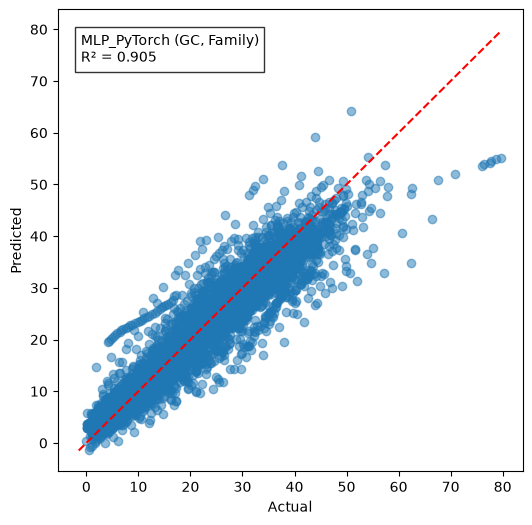

--- MLP_PyTorch | Descriptors | Butina split ---


best params: {'dropout': np.float64(0.18727005942368125), 'hidden_layer_sizes': (128, 64, 32), 'lambda_physics': 0.0, 'lr': np.float64(0.00023273922280628724), 'weight_decay': np.float64(0.0013145103232150123)}
CV metrics per fold - MLP_PyTorch (Descriptors, Butina)


,n_val,RMSE,MAE,r2
1,3410.0,3.313,2.200,0.902
2,3410.0,3.311,2.083,0.902
3,3419.0,4.499,2.500,0.845
4,3410.0,5.691,2.916,0.820
5,3409.0,5.811,2.830,0.761
mean,NaN,4.525,2.506,0.846
std,NaN,1.220,0.369,0.059


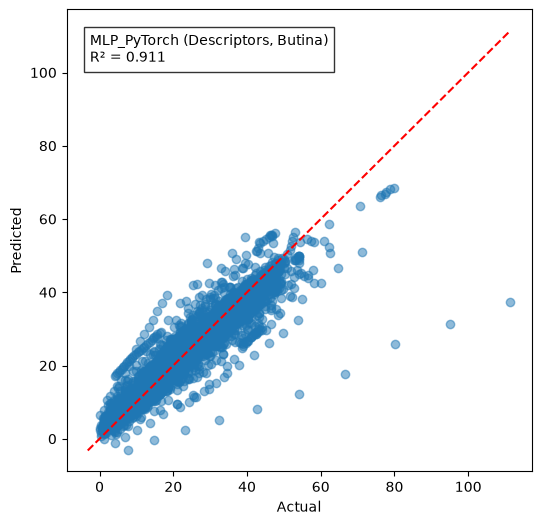

--- MLP_PyTorch | Descriptors | Family split ---


best params: {'dropout': np.float64(0.21597250932105788), 'hidden_layer_sizes': (32,), 'lambda_physics': 0.0, 'lr': np.float64(0.0011208547084229376), 'weight_decay': np.float64(3.9759772143180974e-05)}
CV metrics per fold - MLP_PyTorch (Descriptors, Family)


,n_val,RMSE,MAE,r2
1,3426.0,6.881,3.310,0.755
2,3421.0,4.370,2.553,0.843
3,3426.0,3.806,2.057,0.877
4,3410.0,3.559,2.160,0.894
5,3418.0,3.697,2.284,0.905
mean,NaN,4.463,2.473,0.855
std,NaN,1.386,0.503,0.060


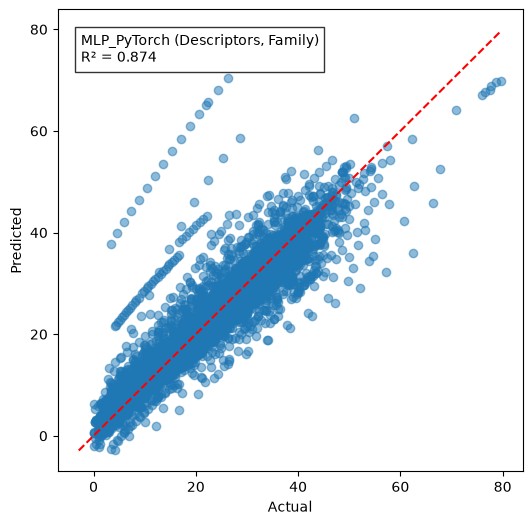

--- MLP_PyTorch_physics | GC | Butina split ---


best params: {'dropout': np.float64(0.18727005942368125), 'hidden_layer_sizes': (128, 64, 32), 'lambda_physics': np.float64(0.0054167545832474575), 'lr': np.float64(0.0036256176345762273), 'weight_decay': np.float64(0.00024400607090817574)}
CV metrics per fold - MLP_PyTorch_physics (GC, Butina)


,n_val,RMSE,MAE,r2
1,3410.0,5.737,4.432,0.705
2,3410.0,5.062,3.969,0.770
3,3419.0,7.037,4.723,0.621
4,3410.0,7.535,4.563,0.684
5,3409.0,5.613,3.754,0.777
mean,NaN,6.197,4.288,0.712
std,NaN,1.041,0.410,0.065


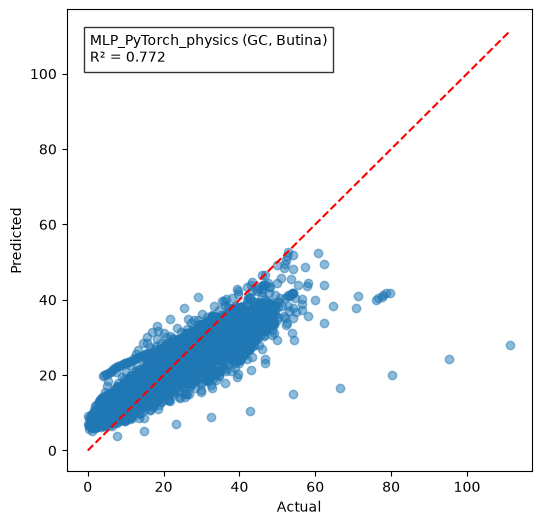

--- MLP_PyTorch_physics | GC | Family split ---


best params: {'dropout': np.float64(0.18727005942368125), 'hidden_layer_sizes': (128, 64, 32), 'lambda_physics': np.float64(0.0054167545832474575), 'lr': np.float64(0.0036256176345762273), 'weight_decay': np.float64(0.00024400607090817574)}
CV metrics per fold - MLP_PyTorch_physics (GC, Family)


,n_val,RMSE,MAE,r2
1,3426.0,8.209,5.111,0.652
2,3421.0,5.472,4.183,0.755
3,3426.0,5.422,4.041,0.750
4,3410.0,5.610,3.955,0.736
5,3418.0,5.717,3.864,0.773
mean,NaN,6.086,4.231,0.733
std,NaN,1.192,0.506,0.047


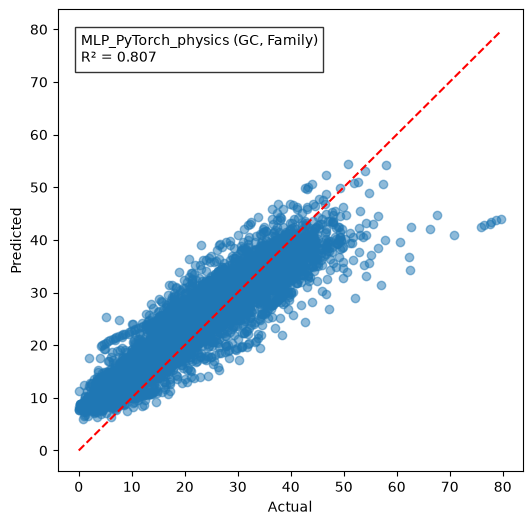

--- MLP_PyTorch_physics | Descriptors | Butina split ---


best params: {'dropout': np.float64(0.22291637642679557), 'hidden_layer_sizes': (64, 32), 'lambda_physics': np.float64(0.068706142826133), 'lr': np.float64(0.0004649617447336333), 'weight_decay': np.float64(3.7279259033769864e-06)}
CV metrics per fold - MLP_PyTorch_physics (Descriptors, Butina)


,n_val,RMSE,MAE,r2
1,3410.0,4.228,3.211,0.840
2,3410.0,4.307,3.436,0.834
3,3419.0,4.888,3.264,0.817
4,3410.0,7.418,4.480,0.694
5,3409.0,6.308,3.780,0.718
mean,NaN,5.430,3.634,0.781
std,NaN,1.389,0.523,0.069


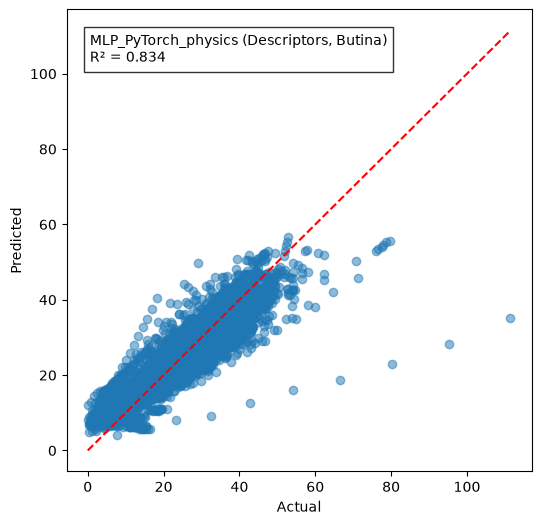

--- MLP_PyTorch_physics | Descriptors | Family split ---


best params: {'dropout': np.float64(0.22007624686980065), 'hidden_layer_sizes': (128, 64), 'lambda_physics': np.float64(0.09565499215943825), 'lr': np.float64(0.00011715937392307068), 'weight_decay': np.float64(0.004337920697490943)}
CV metrics per fold - MLP_PyTorch_physics (Descriptors, Family)


,n_val,RMSE,MAE,r2
1,3426.0,7.725,4.099,0.692
2,3421.0,4.764,3.222,0.814
3,3426.0,4.277,2.901,0.844
4,3410.0,4.411,3.280,0.837
5,3418.0,5.143,3.158,0.816
mean,NaN,5.264,3.332,0.801
std,NaN,1.416,0.452,0.062


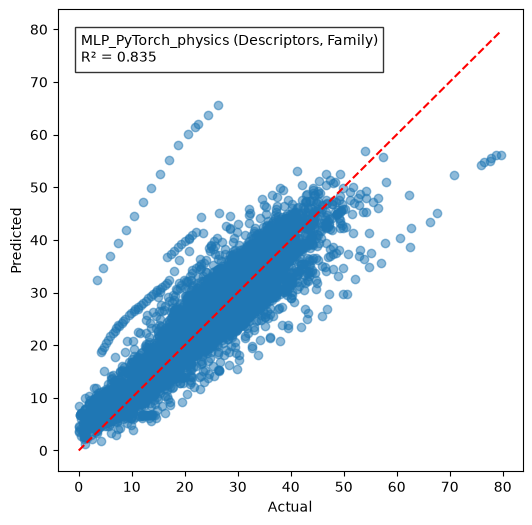

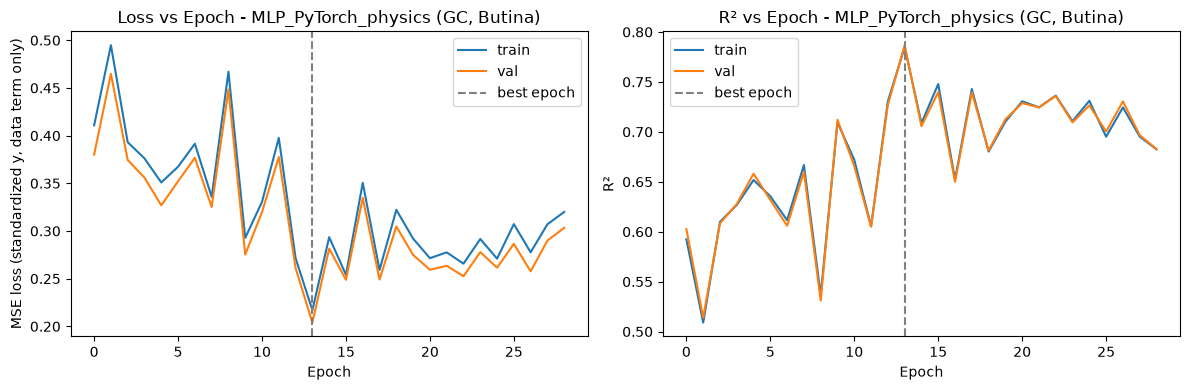

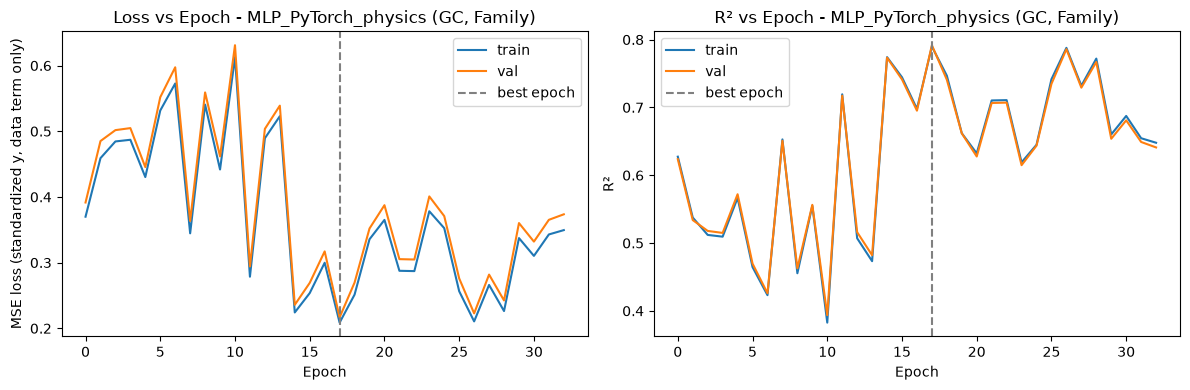

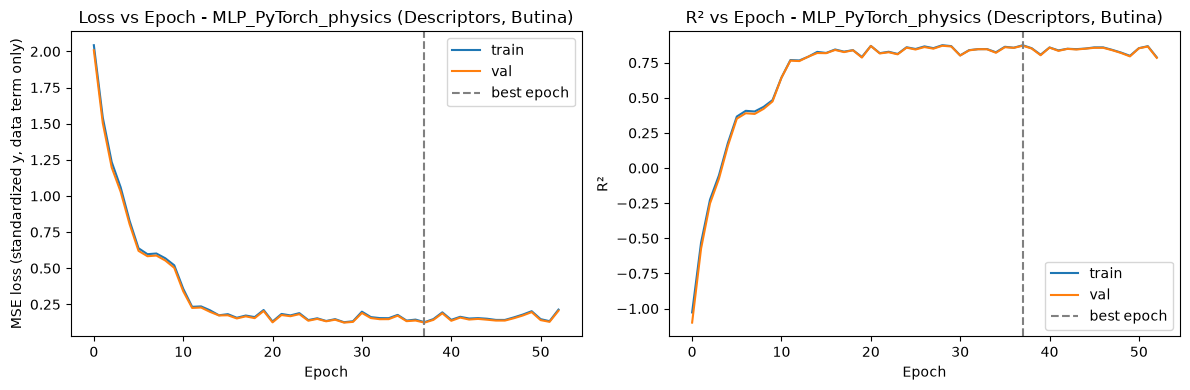

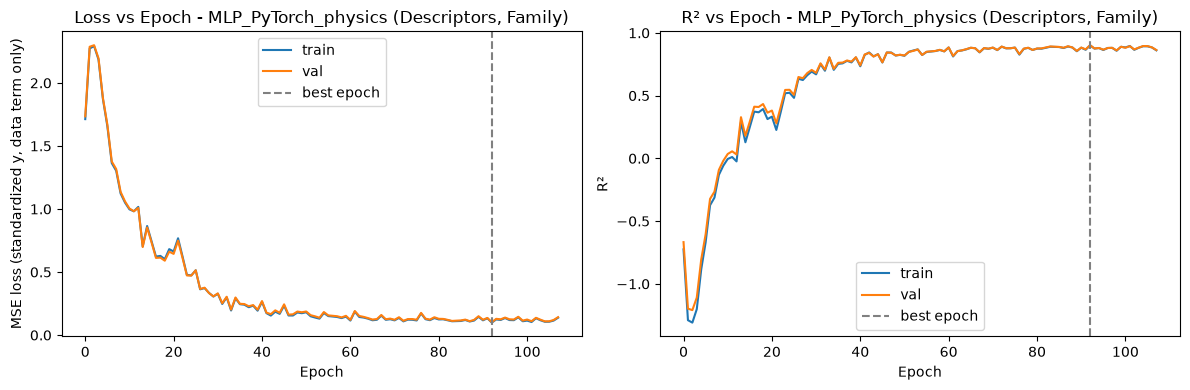

In [18]:
MLP_PARAMS = {
    'hidden_layer_sizes': [(32,), (64,), (64, 32), (128, 64), (128, 64, 32)],
    'dropout': uniform(0.0, 0.5),
    'weight_decay': loguniform(1e-6, 1e-2),
    'lr': loguniform(1e-4, 1e-2),
}

fit_all('MLP_PyTorch', lambda: TorchPhysicsInformedMLP(max_epochs=200, patience=15),
        {**MLP_PARAMS, 'lambda_physics': [0.0]}, pass_tc=True, n_iter=10, n_jobs=1)

fit_all('MLP_PyTorch_physics', lambda: TorchPhysicsInformedMLP(max_epochs=200, patience=15),
        {**MLP_PARAMS, 'lambda_physics': loguniform(1e-3, 1e1)}, pass_tc=True, n_iter=10, n_jobs=1)

for fs in FSETS:
    for s in SPLITS:
        plot_training_curves('MLP_PyTorch_physics', fs, s, f'MLP_PyTorch_physics ({fs}, {s})')

# Baseline vs. physics-informed comparison

The whole point of this notebook: for a comparable test-set RMSE/MAE/r2, does the physics-informed variant show fewer near-TC violations?

### Test-set error metrics

In [19]:
ALGORITHMS = ['XGBoost', 'GradientBoosting', 'RandomForest', 'MLP_PyTorch']

for s in SPLITS:
    m = metrics[s].copy()
    is_physics = m['algorithm'].str.endswith('_physics')
    base = m[~is_physics]
    phys = m[is_physics].copy()
    phys['algorithm'] = phys['algorithm'].str.replace('_physics', '', regex=False)
    merged = base.merge(phys, on=['description', 'algorithm'], suffixes=('_baseline', '_physics'))
    print(f'===== {s} split: baseline vs. physics-informed test metrics =====')
    display(merged[['description', 'algorithm', 'RMSE_baseline', 'RMSE_physics', 'MAE_baseline', 'MAE_physics',
                    'r2_score_baseline', 'r2_score_physics']].sort_values('description').round(3)
            .reset_index(drop=True))

===== Butina split: baseline vs. physics-informed test metrics =====


,description,algorithm,RMSE_baseline,RMSE_physics,MAE_baseline,MAE_physics,r2_score_baseline,r2_score_physics
0,Descriptors,XGBoost,3.477725,3.55439,1.892655,1.962184,0.904198,0.899928
1,Descriptors,GradientBoosting,3.565898,3.6449,2.023284,2.144265,0.899279,0.894766
2,Descriptors,RandomForest,3.82726,3.809053,2.165505,2.129419,0.883973,0.885074
3,Descriptors,MLP_PyTorch,3.350251,4.579971,1.963724,3.358907,0.911093,0.833847
4,GC,XGBoost,3.884902,3.980287,2.237017,2.234398,0.880452,0.874509
5,GC,GradientBoosting,3.992016,4.015201,2.279172,2.406943,0.873769,0.872298
6,GC,RandomForest,4.010517,4.0267,2.385328,2.387939,0.872596,0.871566
7,GC,MLP_PyTorch,3.613948,5.362189,2.10117,3.864377,0.896546,0.772245


===== Family split: baseline vs. physics-informed test metrics =====


,description,algorithm,RMSE_baseline,RMSE_physics,MAE_baseline,MAE_physics,r2_score_baseline,r2_score_physics
0,Descriptors,XGBoost,3.618047,3.47187,2.045247,2.057782,0.888259,0.897106
1,Descriptors,GradientBoosting,3.80826,3.760608,2.189522,2.223081,0.876201,0.87928
2,Descriptors,RandomForest,3.611975,3.60106,2.155598,2.133282,0.888634,0.889306
3,Descriptors,MLP_PyTorch,3.846502,4.394548,2.196056,3.078675,0.873702,0.835149
4,GC,XGBoost,3.706363,3.772063,2.253807,2.276454,0.882738,0.878543
5,GC,GradientBoosting,3.806289,3.741093,2.300873,2.334386,0.876329,0.88053
6,GC,RandomForest,3.825862,3.833035,2.420742,2.429003,0.875054,0.874585
7,GC,MLP_PyTorch,3.327587,4.755549,2.092837,3.730078,0.90548,0.806953


### Critical-point violations

In [20]:
rows = []
for alg in ALGORITHMS:
    for fs in FSETS:
        for s in SPLITS:
            rows.append(tc_violation_counts(alg, fs, s))
            rows.append(tc_violation_counts(f'{alg}_physics', fs, s))
violations = pd.concat(rows, ignore_index=True)

for s in SPLITS:
    print(f'===== {s} split: n_violations, baseline vs. physics-informed =====')
    pivot = violations[violations['split'] == s].pivot_table(
        index=['feature_set', 'T/TC >='], columns='algorithm', values='n_violations')
    display(pivot[[c for pair in ALGORITHMS for c in (pair, f'{pair}_physics')]])

===== Butina split: n_violations, baseline vs. physics-informed =====


algorithm            XGBoost  XGBoost_physics  GradientBoosting  \
feature_set T/TC >=                                               
Descriptors 0.90       199.0            145.0             163.0   
            0.95        28.0              9.0              14.0   
            0.98         4.0              1.0               0.0   
            0.99         3.0              0.0               0.0   
GC          0.90       152.0            127.0             168.0   
            0.95        13.0              7.0              19.0   
            0.98         0.0              1.0               2.0   
            0.99         0.0              0.0               1.0   

algorithm            GradientBoosting_physics  RandomForest  \
feature_set T/TC >=                                           
Descriptors 0.90                        105.0         217.0   
            0.95                          3.0          44.0   
            0.98                          0.0           5.0   
            0.99                          0.0           4.0   
GC          0.90                        112.0         207.0   
            0.95                          4.0          39.0   
            0.98                          0.0           5.0   
            0.99                          0.0           4.0   

algorithm            RandomForest_physics  MLP_PyTorch  MLP_PyTorch_physics  
feature_set T/TC >=                                                          
Descriptors 0.90                    148.0        207.0                217.0  
            0.95                      9.0         38.0                 44.0  
            0.98                      1.0          5.0                  5.0  
            0.99                      0.0          4.0                  4.0  
GC          0.90                    125.0        173.0                217.0  
            0.95                      7.0         18.0                 44.0  
            0.98                      0.0          3.0                  5.0  
            0.99                      0.0          2.0                  4.0

===== Family split: n_violations, baseline vs. physics-informed =====


algorithm            XGBoost  XGBoost_physics  GradientBoosting  \
feature_set T/TC >=                                               
Descriptors 0.90       188.0            128.0             190.0   
            0.95        31.0              7.0              31.0   
            0.98         5.0              1.0               4.0   
            0.99         3.0              0.0               2.0   
GC          0.90       200.0            105.0             185.0   
            0.95        39.0              7.0              31.0   
            0.98         7.0              2.0               7.0   
            0.99         4.0              0.0               4.0   

algorithm            GradientBoosting_physics  RandomForest  \
feature_set T/TC >=                                           
Descriptors 0.90                        110.0         204.0   
            0.95                          6.0          42.0   
            0.98                          1.0           8.0   
            0.99                          0.0           5.0   
GC          0.90                         93.0         202.0   
            0.95                          7.0          42.0   
            0.98                          1.0           8.0   
            0.99                          0.0           5.0   

algorithm            RandomForest_physics  MLP_PyTorch  MLP_PyTorch_physics  
feature_set T/TC >=                                                          
Descriptors 0.90                    139.0        169.0                217.0  
            0.95                     12.0         20.0                 44.0  
            0.98                      3.0          3.0                  8.0  
            0.99                      1.0          1.0                  5.0  
GC          0.90                    131.0        200.0                217.0  
            0.95                     14.0         36.0                 44.0  
            0.98                      4.0          7.0                  8.0  
            0.99                      2.0          4.0                  5.0

### Detailed audit (one example model per algorithm)

Full `check_tc_violations` output (plots + worst offenders), baseline vs. physics-informed, for the GC feature set on the Butina split.

In [21]:
for alg in ALGORITHMS:
    check_tc_violations(alg, 'GC', 'Butina')
    check_tc_violations(f'{alg}_physics', 'GC', 'Butina')

Critical-point violations (predicted Surface_tension > 2.0 mN/m near TC) - XGBoost (GC, Butina)


,T/TC >=,n_rows,n_violations
0,0.90,217,152
1,0.95,44,13
2,0.98,5,0
3,0.99,4,0


15 worst violations (closest to TC, by T/TC) - XGBoost (GC, Butina)


,ChemID,Family,T,TC,actual,predicted,Tr
4896,23340,GLYCERIDES,936.25,966.40,0.423,3.403,0.969
4730,1378,AROMATIC ESTERS,839.64,870.00,0.947,2.657,0.965
4346,9899,POLYFUNCTIONAL ESTERS,823.03,853.90,1.331,5.415,0.964
8166,2649,"C, H, MULTIHALOGEN COMPOUNDS",462.65,481.00,0.814,2.981,0.962
4918,21381,AROMATIC ESTERS,747.98,779.00,1.964,2.245,0.960
4660,9866,"POLYFUNCTIONAL C, H, O, N",705.83,736.00,1.669,6.212,0.959
4401,1354,AROMATIC ESTERS,804.90,840.00,0.722,3.186,0.958
1423,2628,"C, H, F COMPOUNDS",432.35,451.55,0.915,2.301,0.957
4153,1792,AROMATIC AMINES,673.52,705.00,1.614,2.718,0.955
4327,3119,AROMATIC ALCOHOLS,668.60,700.00,1.550,2.147,0.955


Critical-point violations (predicted Surface_tension > 2.0 mN/m near TC) - XGBoost_physics (GC, Butina)


,T/TC >=,n_rows,n_violations
0,0.90,217,127
1,0.95,44,7
2,0.98,5,1
3,0.99,4,0


... (22 outputs left out)

Critical-point violations (predicted Surface_tension > 2.0 mN/m near TC) - MLP_PyTorch_physics (GC, Butina)


,T/TC >=,n_rows,n_violations
0,0.90,217,217
1,0.95,44,44
2,0.98,5,5
3,0.99,4,4


15 worst violations (closest to TC, by T/TC) - MLP_PyTorch_physics (GC, Butina)


,ChemID,Family,T,TC,actual,predicted,Tr
3856,1035,ALDEHYDES,554.14,554.00,4.451,7.604,1.000
2557,2801,ISOCYANATES/DIISOCYANATES,765.00,765.00,0.398,6.606,1.000
2602,1275,OTHER ALIPHATIC ACIDS,694.00,694.00,0.000,6.929,1.000
3862,5892,"POLYFUNCTIONAL C, H, O, N",589.00,590.00,0.092,9.174,0.998
1424,2628,"C, H, F COMPOUNDS",442.89,451.55,0.203,8.599,0.981
2485,1625,"C, H, F COMPOUNDS",488.75,502.30,0.370,6.696,0.973
4896,23340,GLYCERIDES,936.25,966.40,0.423,5.696,0.969
5556,3728,OTHER ALIPHATIC AMINES,710.00,734.00,1.594,6.800,0.967
4730,1378,AROMATIC ESTERS,839.64,870.00,0.947,7.047,0.965
4346,9899,POLYFUNCTIONAL ESTERS,823.03,853.90,1.331,7.082,0.964
